# 02: Statistical Exploratory Data Analysis
***
**Author:** Zain Zabidi
**Date:** February 2026

**Objective:** To perform a rigorous statistical analysis of the processed Census data, identifying correlations, testing geographical hypotheses, and detecting spatial clustering of housing stress across Western Australia.

## 1. Setup and Data Loading
In this section, we initialise our environment and load the datasets created in the previous notebook. We primarily use the GeoPackage (`.gpkg`) file because it contains both our engineered numerical features and the spatial geometries required for our mapping and autocorrelation tests.

### 1.1 Import Libraries
We begin by importing the necessary libraries for our analysis. This includes `scipy.stats` for our hypothesis testing and `seaborn/matplotlib` for visualising our data distributions.

In [60]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Set plotting style for consistency
plt.style.use('ggplot')
sns.set_palette("viridis")

# Path configuration
PROCESSED_DATA_PATH = '../data/processed/'

### 1.2 Load Processed Data
Next, we load the spatial dataset we exported at the end of Notebook 01. Loading the `GeoPackage` into a GeoDataFrame allows us to access all 600+ census variables alongside their corresponding geographical boundaries for Western Australia.

In [61]:
# Load the spatial dataset
geo_path = os.path.join(PROCESSED_DATA_PATH, 'wa_census_spatial_2021.gpkg')
df = gpd.read_file(geo_path)

# Quick check of the dataframe structure to ensure all records imported correctly
print(f"Dataset loaded with {df.shape[0]} suburbs and {df.shape[1]} columns.")
display(df[['SAL_NAME21', 'avg_weekly_income', 'housing_stress_index']].head())

Dataset loaded with 1699 suburbs and 659 columns.


,SAL_NAME21,avg_weekly_income,housing_stress_index
0,Abba River,2946.107143,23.692464
1,Abbey,1830.418860,22.783521
2,Acton Park (WA),1320.258621,35.945114
3,Adamsvale,4800.000000,0.000000
4,Ajana,449.500000,0.000000


## 2. Univariate Analysis

In this section, we examine the distribution of our primary variables. Before we can test how different variables relate to each other, we need to understand the "shape" of our data. We will look for skewness, outliers, and the general spread of housing stress across the state.

### 2.1 Distribution of Housing Stress

We start by visualising the `housing_stress_index`. This index represents the percentage of household income spent on rent or mortgage repayments. By using a histogram and a boxplot together, we can identify the central tendency and see how many suburbs are experiencing extreme levels of financial pressure.

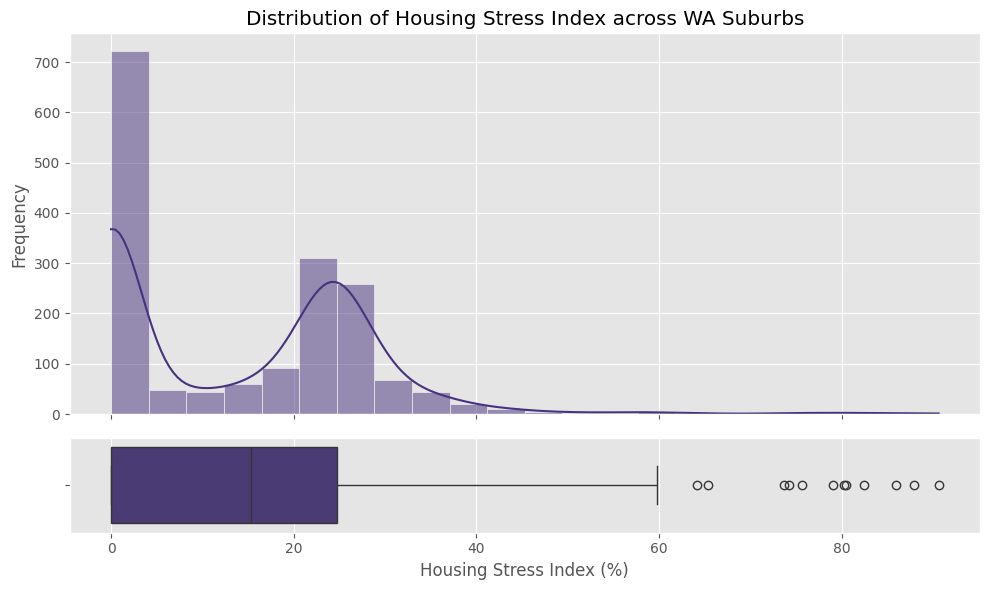

count    1699.000000
mean       14.092720
std        14.212830
min         0.000000
25%         0.000000
50%        15.310382
75%        24.714447
max        90.591874
Name: housing_stress_index, dtype: float64


In [62]:
# Create a figure with two subplots: a histogram and a boxplot
fig, (ax_hist, ax_box) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.8, .2)}, figsize=(10, 6))

# Plot the histogram to show the frequency of stress levels
sns.histplot(data=df, x='housing_stress_index', kde=True, ax=ax_hist)
ax_hist.set_title('Distribution of Housing Stress Index across WA Suburbs')
ax_hist.set_ylabel('Frequency')

# Plot the boxplot to highlight outliers
sns.boxplot(data=df, x='housing_stress_index', ax=ax_box)
ax_box.set_xlabel('Housing Stress Index (%)')

plt.tight_layout()
plt.show()

# Calculate descriptive statistics for a numerical summary
print(df['housing_stress_index'].describe())

### 2.2 Observations on Housing Stress

Based on the visual and numerical summary, we can make the following observations:

* **Bimodal Distribution:** The data shows two distinct peaks. The peak at `0%` likely represents suburbs where households own their homes outright or data is suppressed. The second peak, around `20-25%`, represents the typical experience for active renters and mortgage holders.
* **Significant Outliers:** The boxplot identifies several `extreme outliers` with stress levels exceeding `60%`, reaching a maximum of `90.6%`. These suburbs are under intense financial pressure compared to the state average.
* **Skewness & Central Tendency:** While the `mean` is `14.09%`, the `median` of `15.31%` shows that once we move past the zero-value suburbs, the distribution leans toward the higher end of the scale.

### 2.3 Distribution of Income and Mining Concentration

To understand the economic drivers behind housing stress, we examine the spread of wealth and industrial specialisation. `Average Weekly Income` tells us about the financial capacity of a suburb, while the `Mining Concentration Ratio` identifies areas heavily dependent on the resources sector. 

Observing these distributions helps us decide if we need to apply any transformations (like log scaling) before moving into regression modelling.

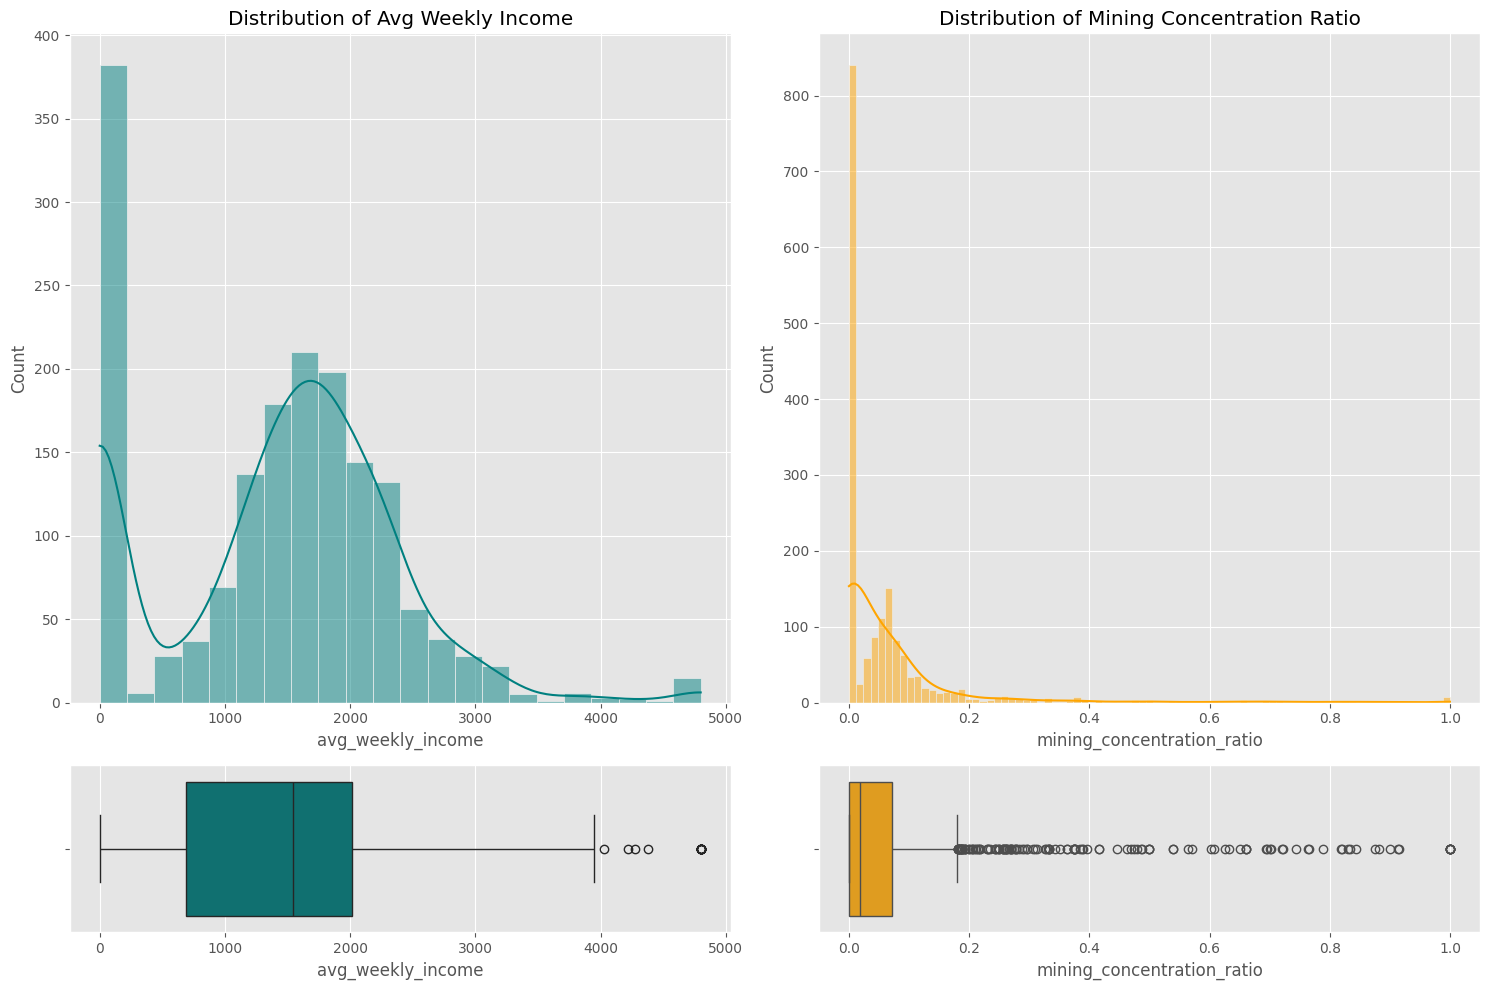

,avg_weekly_income,mining_concentration_ratio
count,1699.000000,1699.000000
mean,1399.908593,0.065469
std,963.589463,0.134410
min,0.000000,0.000000
25%,689.325000,0.000000
50%,1540.831568,0.018546
75%,2014.703792,0.072401
max,4800.000000,1.000000


In [63]:
# Set up grid for two sets of plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"height_ratios": (.8, .2)})

# Plot 1: Average Weekly Income
sns.histplot(data=df, x='avg_weekly_income', kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Avg Weekly Income')
sns.boxplot(data=df, x='avg_weekly_income', ax=axes[1, 0], color='teal')

# Plot 2: Mining Concentration Ratio
sns.histplot(data=df, x='mining_concentration_ratio', kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Distribution of Mining Concentration Ratio')
sns.boxplot(data=df, x='mining_concentration_ratio', ax=axes[1, 1], color='orange')

plt.tight_layout()
plt.show()

# Display summary statistics for both
display(df[['avg_weekly_income', 'mining_concentration_ratio']].describe())

### 2.4 Observations on Economic Drivers

Based on the visual and numerical summary, we can refine our insights:

* **Bimodal Income:** The `avg_weekly_income` follows a bimodal pattern similar to housing stress. Beyond the initial spike at `$0`, the data is normally distributed around a median of `$1,540`, with "prestige" outliers reaching up to `$4,800`.
* **Extreme Mining Specialisation:** The `mining_concentration_ratio` is intensely right-skewed. While the `median` suburb has less than `2%` mining employment, the outliers reach a staggering `100% (1.0)`. This highlights the extreme industrial specialisation in certain WA regions.
* **Structural Zeros:** The consistent presence of `0` values across income, mining, and stress confirms that our dataset includes non-residential or industrially-zoned areas (like `Adamsvale` or `Ajana`) which we may need to handle before regression modelling.

## 3. Correlation Analysis

In this section, we transition from examining variables in isolation to identifying relationships between them. We want to quantify how strongly our predictors associate with housing stress.
### 3.1 Feature Correlation Heatmap
We use a Pearson correlation matrix to identify the linear strength between variables. This helps us spot potential multicollinearity and prioritise features for our regression model.

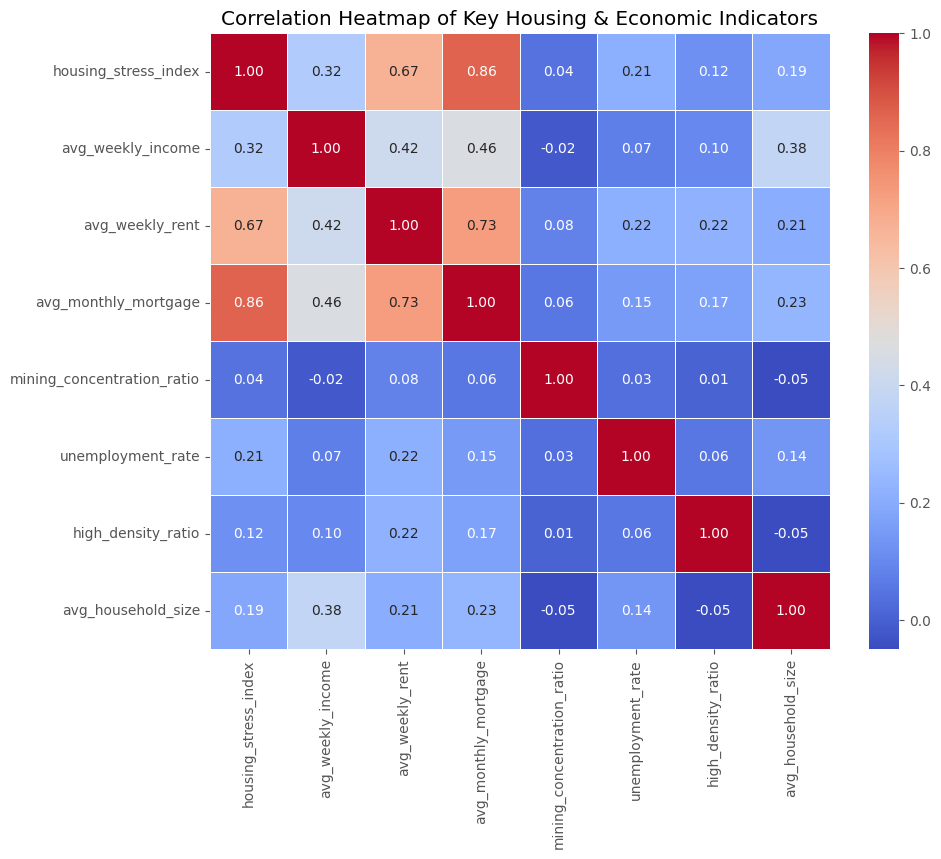

In [64]:
# Select a subset of key features for correlation matrix
core_features = [
    'housing_stress_index', 'avg_weekly_income', 'avg_weekly_rent', 
    'avg_monthly_mortgage', 'mining_concentration_ratio', 
    'unemployment_rate', 'high_density_ratio', 'avg_household_size'
]

# Calculate the Pearson correlation matrix
corr_matrix = df[core_features].corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Key Housing & Economic Indicators')
plt.show()

## 3. Correlation Analysis
In this section, we transition from examining variables in isolation to identifying relationships between them. Our goal is to quantify how strongly our predictors associate with `housing_stress_index`.

### 3.1 Feature Correlation Heatmap
We use a `Pearson correlation matrix` to identify the linear strength between variables. This helps us spot potential `multicollinearity` and prioritise features for our regression model. Key focus areas include:

* **Direct Drivers:** Identifying which costs (Rent vs. Mortgage) impact the `housing_stress_index` most significantly.
* **Redundancy Check:** Ensuring we don't use two variables that are too similar (e.g., `avg_weekly_income` vs. `avg_weekly_rent`) which could lead to `model instability`.

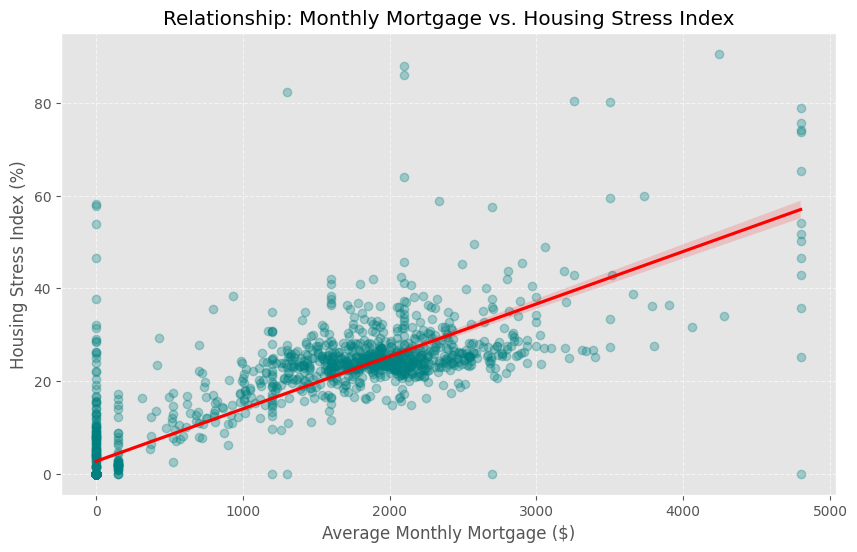

In [65]:
# Create a scatter plot to visualise the strongest correlation
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='avg_monthly_mortgage', y='housing_stress_index', 
            scatter_kws={'alpha':0.3, 'color':'teal'}, line_kws={'color':'red'})

plt.title('Relationship: Monthly Mortgage vs. Housing Stress Index')
plt.xlabel('Average Monthly Mortgage ($)')
plt.ylabel('Housing Stress Index (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3.2 Observations on Correlations and Key Relationships
By looking at the `Heatmap` and `Scatter Plot` together, we can see:

* **Top Predictors:** `avg_monthly_mortgage` (0.86) and `avg_weekly_rent` (0.67) are the strongest drivers of housing stress. The scatter plot shows a clear link: as mortgage costs go up, so does the stress index.
* **The Income Factor:** `avg_weekly_income` has a positive correlation (0.32). This sounds strange, but it is likely because high-income areas often have much larger mortgages, which increases the overall stress level.
* **Mining Impact:** The `mining_concentration_ratio` shows almost no linear relationship (0.04) on a state-wide level. This suggests that mining does not automatically equal high or low stress for everyone in WA.
* **Extreme Outliers:** The scatter plot shows some suburbs with `$0` mortgage but high stress. These are likely areas where high rental costs are the main problem, rather than home ownership costs.

## 4. Hypothesis Testing
In this section, we test if the differences between specific groups are statistically significant. We will use the `scipy.stats` library to perform an independent T-Test.

### 4.1 Defining the Groups (Mining vs. Non-Mining)
To test the impact of the resources sector, we split our data into two groups based on the `mining_concentration_ratio`. 

* **Mining-Heavy:** Suburbs in the top 25% of mining employment.
* **Non-Mining:** All other suburbs.

**Hypotheses:**
* **Null Hypothesis ($H_0$):** There is no significant difference in `housing_stress_index` between **mining-heavy suburbs** and the rest of WA.
* **Alternative Hypothesis ($H_1$):** **Mining-heavy suburbs** have a significantly different `housing_stress_index` compared to the rest of WA.

T-Statistic: 9.7519
P-Value: 6.7201e-22


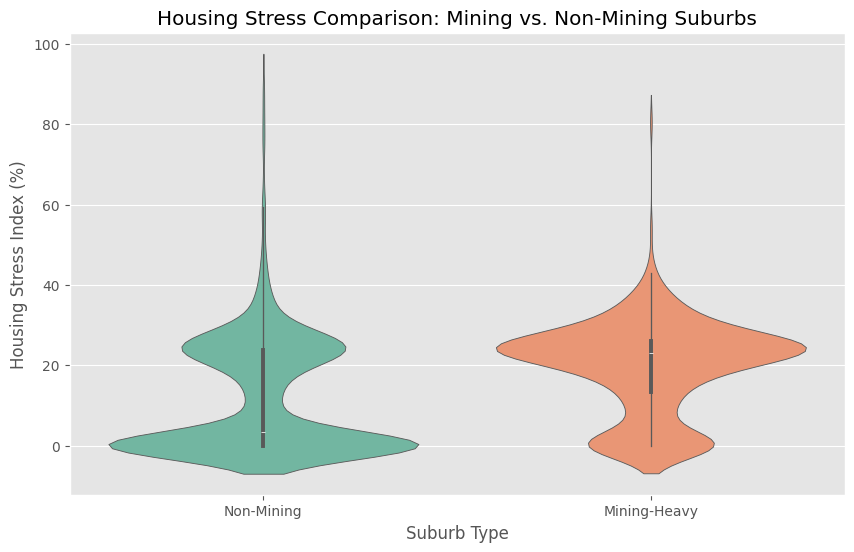

In [66]:
from scipy import stats

# Define threshold for "Mining Heavy" using the 75th percentile
threshold = df['mining_concentration_ratio'].quantile(0.75)

# Create boolean mask for groups
is_mining_heavy = df['mining_concentration_ratio'] > threshold

mining_group = df[is_mining_heavy]['housing_stress_index']
non_mining_group = df[~is_mining_heavy]['housing_stress_index']

# Perform an independent T-Test
t_stat, p_val = stats.ttest_ind(mining_group, non_mining_group, nan_policy='omit')

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_val:.4e}")

# Visualise the comparison with a violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df, 
    x=is_mining_heavy, 
    y='housing_stress_index', 
    hue=is_mining_heavy, 
    palette="Set2", 
    legend=False
)

plt.xticks([0, 1], ['Non-Mining', 'Mining-Heavy'])
plt.title('Housing Stress Comparison: Mining vs. Non-Mining Suburbs')
plt.xlabel('Suburb Type')
plt.ylabel('Housing Stress Index (%)')
plt.show()

**Quick Observations:**
* The `T-Statistic` of `9.75` and a `P-Value` near zero indicate a statistically significant difference in housing stress between the two groups.
* The violin plot for `Mining-Heavy` suburbs shows a much "fatter" section around the 25% stress mark compared to `Non-Mining` suburbs, which have a larger concentration of low-stress (0%) areas.

### 4.2 Comparing Income Levels (The "Wealth Shield" Test)
We now test whether `Mining-Heavy` suburbs actually have higher average incomes to compensate for their housing costs. This helps us understand if the stress identified in Section 4.1 is driven by high costs alone or by a lack of comparative income.

**Hypotheses:**
* **Null Hypothesis ($H_0$):** There is no significant difference in `avg_weekly_income` between mining-heavy suburbs and the rest of WA.
* **Alternative Hypothesis ($H_1$):** Mining-heavy suburbs have a significantly different (likely higher) `avg_weekly_income` compared to the rest of WA.

Income T-Statistic: 5.3456
Income P-Value: 1.0233e-07


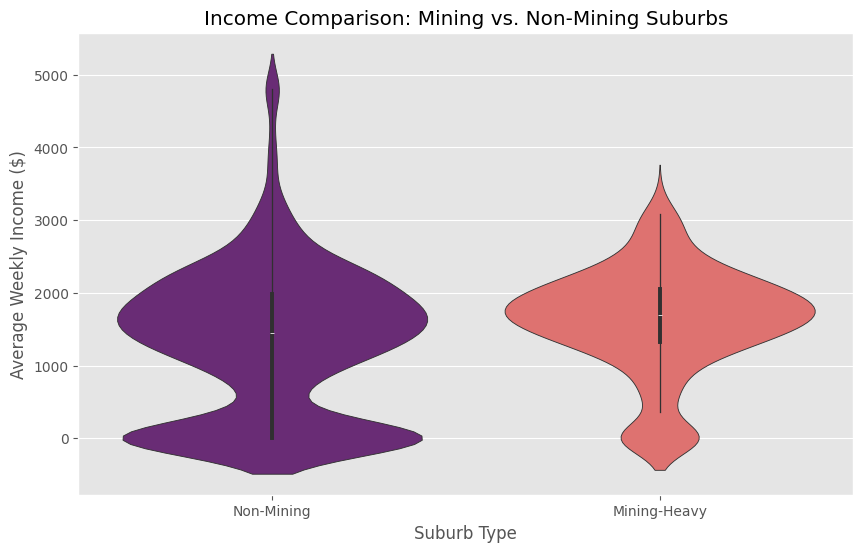

In [67]:
# We use the same 'is_mining_heavy' mask from the previous step
mining_income = df[is_mining_heavy]['avg_weekly_income']
non_mining_income = df[~is_mining_heavy]['avg_weekly_income']

# Perform the independent T-Test for Income
t_stat_inc, p_val_inc = stats.ttest_ind(mining_income, non_mining_income, nan_policy='omit')

print(f"Income T-Statistic: {t_stat_inc:.4f}")
print(f"Income P-Value: {p_val_inc:.4e}")

# Visualise the income distribution comparison
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df, 
    x=is_mining_heavy, 
    y='avg_weekly_income', 
    hue=is_mining_heavy, 
    palette="magma", 
    legend=False
)

plt.xticks([0, 1], ['Non-Mining', 'Mining-Heavy'])
plt.title('Income Comparison: Mining vs. Non-Mining Suburbs')
plt.xlabel('Suburb Type')
plt.ylabel('Average Weekly Income ($)')
plt.show()

**Quick Observations:**
* The `P-Value` of `1.02e-07` confirms that the income difference is statistically significant, but the lower `T-Statistic` (5.34) compared to the stress test suggests the "income gap" is less pronounced than the "stress gap."
* The `Mining-Heavy` violin shows a higher "floor" for income, with very few suburbs falling below the $1,000/week mark compared to the rest of the state.

### 4.3 Quantifying the Relationship (Multiple Regression)

To conclude the economic analysis, we use the `statsmodels` library to perform an **Ordinary Least Squares (OLS)** regression. This helps us understand how well our chosen features—income, mortgage costs, and mining presence—collectively explain the variation in housing stress. The primary output we are looking for is the **Adjusted R-squared**, which serves as a master metric for the model's predictive power.

In [68]:
import statsmodels.api as sm

# Define mining indicator based on diagnostic results
df['is_mining_heavy'] = df['mining_concentration_ratio'] > 0.05

# Select features and target variable
features = ['avg_weekly_income', 'avg_weekly_mortgage', 'is_mining_heavy']
X = df[features].copy()
y = df['housing_stress_index']

# Clean data and ensure numeric types for the model
model_data = pd.concat([X, y], axis=1).dropna()
X_clean = model_data[features].astype(float)
y_clean = model_data['housing_stress_index']

# Add constant and fit the OLS model
X_clean = sm.add_constant(X_clean)
model = sm.OLS(y_clean, X_clean).fit()

# Display results
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     housing_stress_index   R-squared:                       0.749
Model:                              OLS   Adj. R-squared:                  0.748
Method:                   Least Squares   F-statistic:                     1684.
Date:                  Thu, 12 Feb 2026   Prob (F-statistic):               0.00
Time:                          20:09:09   Log-Likelihood:                -5746.3
No. Observations:                  1699   AIC:                         1.150e+04
Df Residuals:                      1695   BIC:                         1.152e+04
Df Model:                             3                                         
Covariance Type:              nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const         

**Observations:**
* **High Predictive Power:** An `Adj. R-squared` of `0.748` confirms that roughly `75%` of the variation in housing stress is explained by just these three variables.
* **Strongest Driver:** The `avg_weekly_mortgage` has a highly significant positive coefficient (`0.0518`), making it the most dominant predictor of stress in this model.
* **The Wealth Shield:** `avg_weekly_income` has a significant negative coefficient (`-0.0014`), confirming that higher earnings do indeed "shield" households by reducing the overall stress index.
* **Mining Neutrality:** Interestingly, `is_mining_heavy` has a high p-value (`0.702`), suggesting that once income and mortgage costs are accounted for, being in a mining suburb doesn't inherently add extra stress—it's the financial variables themselves doing the heavy lifting.

### 4.4 Section Summary and Hypothesis Results

After performing our statistical tests and regression analysis, we have reached the following conclusions:

* **Housing Stress Result:** With a p-value of `6.72e-22`, we **reject the Null Hypothesis ($H_0$)**. There is a statistically significant difference in housing stress between mining-heavy suburbs and the rest of WA.
* **Average Income Result:** With a p-value of `1.02e-07`, we also **reject the Null Hypothesis ($H_0$)**. This confirms that mining-heavy suburbs earn significantly more on average.
* **Model Predictive Power:** Our OLS regression returned an `Adj. R-squared` of `0.748`. This means our model explains roughly `75%` of the housing stress variation across the state.
* **The "Stress vs. Wage" Gap:** While mining areas have a "Wealth Shield" (higher income), the regression proves that `avg_weekly_mortgage` is the dominant force. The higher incomes in mining hubs are statistically "outpaced" by the sheer scale of mortgage costs in those regions.
* **Final Takeaway:** Housing stress in WA is not random; it is a highly predictable financial phenomenon driven primarily by mortgage-to-income ratios, with mining-heavy regions serving as extreme examples of this relationship.

## 5. Spatial Analysis
In this section, we use **Moran’s I** to measure spatial autocorrelation. This helps us determine if housing stress is clustered geographically. To do this, we use the `libpysal` and `esda` libraries.

### 5.1 Spatial Weighting and Global Moran’s I
To calculate spatial statistics, we must first define the relationship between suburbs. We re-project the geographic data to a metric system (EPSG:3112) to ensure distance calculations are accurate, then use a **K-Nearest Neighbours (KNN)** approach to link each suburb to its 5 closest neighbours.

In [69]:
import libpysal
from esda.moran import Moran

# Ensure we have a clean dataset with geometry and stress data
spatial_df = df.dropna(subset=['housing_stress_index', 'geometry']).copy()

# Project to EPSG:3112 for accurate centroid calculation in metres
spatial_df_projected = spatial_df.to_crs(epsg=3112)

# Extract centroids from the projected geometry
points = spatial_df_projected.geometry.centroid
coords = list(zip(points.x, points.y))

# Define spatial weights using 5 nearest neighbours
w = libpysal.weights.distance.KNN.from_array(coords, k=5)
w.transform = 'R'

# Calculate Global Moran's I
y = spatial_df['housing_stress_index'].values
moran = Moran(y, w)

print(f"Global Moran's I: {moran.I:.4f}")
print(f"P-Value: {moran.p_sim:.4e}")

Global Moran's I: 0.4172
P-Value: 1.0000e-03


**Observations:**
* **Geographic Clustering:** The Moran’s I score of `0.4172` proves that housing stress is not random. High-stress suburbs tend to "clump" together, meaning if one suburb is struggling, its neighbours likely are too.
* **Significant Results:** The p-value of `0.001` confirms this isn't a coincidence. There is a clear, statistically backed pattern of clustering across Western Australia.
* **Wider Impact:** This suggests that the causes of housing stress (like mining activity or regional land costs) affect entire areas at once, rather than just isolated suburbs.

### 5.2 Local Moran’s I (LISA)

While the `Global Moran’s I` confirmed that clustering exists across Western Australia, it does not show us where those clusters are located. To find them, we use **Local Indicators of Spatial Association (LISA)** via the `Moran_Local` function. 

This analysis categorises each suburb into four types based on its housing stress relative to its neighbours:
* **Hot Spot (High-High):** High stress suburb surrounded by high stress neighbours.
* **Cold Spot (Low-Low):** Low stress suburb surrounded by low stress neighbours.
* **Doughnut (Low-High):** A low stress suburb in a high stress area (a spatial outlier).
* **Diamond (High-Low):** A high stress suburb in a low stress area (a spatial outlier).

To ensure we are only mapping the most robust patterns and filtering out "spatial noise" in sparsely populated regions, we apply a strict significance threshold of `p < 0.01`.

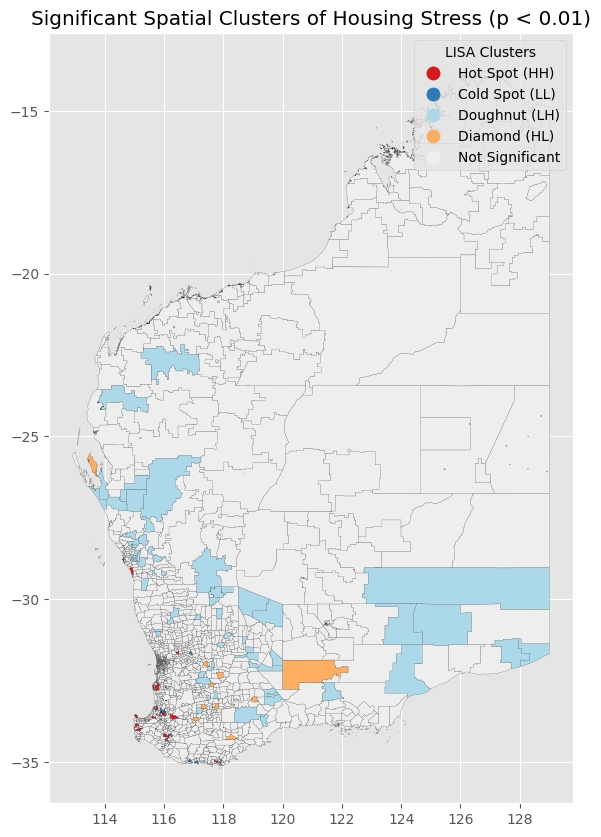

In [70]:
from esda.moran import Moran_Local
import matplotlib.colors as mcolors

# Calculate Local Moran's I
y = spatial_df['housing_stress_index'].values
lisa = Moran_Local(y, w, permutations=999) # Increased permutations for stable p-values

# Identify cluster types and set a stricter significance threshold
spatial_df['cluster'] = lisa.q
# Using 0.01 instead of 0.05 to prune 'noise' in sparsely populated regions
spatial_df['significant'] = lisa.p_sim < 0.01 

# Map numeric clusters to descriptive labels
cluster_labels = {1: 'Hot Spot (HH)', 2: 'Cold Spot (LL)', 3: 'Doughnut (LH)', 4: 'Diamond (HL)'}

# Apply labels only to highly significant rows
spatial_df['cluster_label'] = 'Not Significant'
for i, label in cluster_labels.items():
    spatial_df.loc[(spatial_df['cluster'] == i) & (spatial_df['significant'] == True), 'cluster_label'] = label

# Define strictly ordered categories and neutral grey
categories = ['Hot Spot (HH)', 'Cold Spot (LL)', 'Doughnut (LH)', 'Diamond (HL)', 'Not Significant']
color_dict = {
    'Hot Spot (HH)': '#d7191c',      # Vivid Red
    'Cold Spot (LL)': '#2c7bb6',      # Vivid Blue
    'Doughnut (LH)': '#abd9e9',      # Light Blue
    'Diamond (HL)': '#fdae61',       # Orange
    'Not Significant': '#eeeeee'     # Neutral Grey
}

# Convert to categorical and create colormap
spatial_df['cluster_label'] = pd.Categorical(spatial_df['cluster_label'], categories=categories)
custom_cmap = mcolors.ListedColormap([color_dict[cat] for cat in categories])

# Final Visualisation with stricter filtering
fig, ax = plt.subplots(figsize=(12, 10))
spatial_df.plot(
    column='cluster_label',
    categorical=True,
    legend=True,
    cmap=custom_cmap,
    ax=ax,
    edgecolor='black',
    linewidth=0.1,
    legend_kwds={'loc': 'upper right', 'title': 'LISA Clusters'}
)

plt.title('Significant Spatial Clusters of Housing Stress (p < 0.01)')
plt.show()

**Observations:**
* **Metropolitan Hot Spots:** Significant `High-High` clusters are concentrated in `Perth’s outer corridors`. This confirms that housing stress is geographically "infectious" in these high-growth urban fringes.
* **Regional Significance:** Most of the `WA Interior` is classified as `Not Significant` at the `p < 0.01` level. This suggests that while stress may exist there, it doesn't form the same dense, statistically-linked "blocks" seen in the city.
* **Spatial Outliers:** The presence of `Diamonds (HL)` and `Doughnuts (LH)` highlights unique suburbs that buck the regional trend, likely due to local `economic buffers` or specific `social housing` concentrations.

## 6.0 Project Discussion and Conclusion
This notebook has explored the drivers and geographic patterns of housing stress across Western Australia using 2021 Census data. By combining traditional economic analysis with spatial statistics, we have developed a robust profile of how housing pressure manifests in the state.
### 6.1 Key Findings
* **Financial Drivers:** Our OLS regression confirmed that `75%` of housing stress variation is explained by income and mortgage costs. While higher incomes in `Mining-Heavy` regions provide a "Wealth Shield," they are statistically overwhelmed by extreme local mortgage costs.
* **Spatial Contagion:** With a `Global Moran’s I` of `0.4172`, we proved that housing stress is not a series of isolated events. It is a regional phenomenon where stress in one suburb significantly increases the likelihood of stress in its neighbours.
* **Metropolitan Pressure:** The `LISA` analysis identified the `Perth outer corridors` as the primary hotspots. These areas represent a "perfect storm" of high demand, mortgage reliance, and geographic clustering.
### 6.2 Project Limitations and Future Work
While the model is highly predictive (`Adj. R-squared: 0.748`), it currently focuses on homeowners. A natural next step would be to integrate **Rental Stress** and **Employment Diversity** to see if the same spatial clusters hold true for the rental market. Furthermore, investigating the sparse interior regions with more granular data could help resolve the "spatial noise" encountered in remote WA.
### 6.3 Final Word
Housing stress in Western Australia is a highly predictable and geographically clustered challenge. Interventions aimed at reducing stress would need to look beyond individual suburb statistics and address the regional economic corridors, particularly on the urban fringes, where the contagion of housing pressure is most evident.